# Intro

* How to copy weights between two models
* How to "freeze" weights during training

# Imports

In [1]:
import numpy as np
import requests
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn
from torch.nn import functional as F

from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

# Add test set

In [3]:
# download and tokenize the text
text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text
tm_tokens = torch.tensor(tokenizer.encode(text))
len(tm_tokens)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (45295 > 1024). Running this sequence through the model will result in indexing errors


45295

# Hyperparams

In [4]:
seq_len = 8
stride = 2

embed_dim = 768

batch_size = 64

n_vocab = tokenizer.vocab_size

# Create Train and Test Set

In [5]:
text = requests.get('http://www.gutenberg.org/files/35/35-0.txt').text
tm_tokens = torch.tensor(tokenizer.encode(text))
len(tm_tokens)

45295

In [6]:
class TokenDataset(Dataset):
  def __init__(self, tokens, seq_len=9, stride=4):

    # initialize
    self.inputs  = []
    self.targets = []

    # overlapping sequences of seq_len

    for i in range(0, len(tokens)-seq_len, stride):

      # get c tokens and append to the lists
      self.inputs.append(tokens[i:i+seq_len])
      self.targets.append(tokens[i+1:i+seq_len+1])

  def __len__(self):
    return len(self.inputs)

  def __getitem__(self, idx):
    return self.inputs[idx], self.targets[idx]

In [7]:
# create an instance
token_dataset = TokenDataset(tm_tokens, seq_len, stride)

# split into train and test
train_ratio = .9
train_size  = int(train_ratio * len(token_dataset))
test_size   = len(token_dataset) - train_size

# create train/test subsets
train_dataset, test_dataset = random_split(
    token_dataset, [train_size, test_size]
)

# create DataLoaders
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader  = DataLoader(test_dataset,  batch_size = batch_size, shuffle = False)

print(f'Train set has {train_size:5} sequences.')
print(f'Test set has {test_size:5} sequences.')

Train set has 20379 sequences.
Test set has  2265 sequences.


# Model

In [8]:
# Model
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    self.embedding = nn.Embedding(n_vocab, embed_dim)
    self.gelu      = nn.GELU()
    self.linear    = nn.Linear(embed_dim, n_vocab)

  def forward(self, x):
    x = self.embedding(x)
    x = self.gelu(x)
    x = self.linear(x)
    return F.log_softmax(x, dim = -1)

  def generate(self, tok_x, n_tok_predict = 30):

    for i in range(n_tok_predict):
      output   = self(tok_x)
      logits   = output[:,-1,:] # [B, T, N_VOCAB]
      probs    = torch.exp(logits)
      next_tok = torch.multinomial(probs, num_samples = 1)
      tok_x = torch.cat((tok_x, next_tok), dim = 1)

    return tok_x

In [9]:
model = Model()
X, y = token_dataset[1]
out = model(X)

print(X.shape)
print(y.shape)
print(out.shape)

torch.Size([8])
torch.Size([8])
torch.Size([8, 50257])


# Train the data with frozen embeddings

## Copy GPT2's Embeddings onto Model 1

In [10]:
from transformers import AutoModelForCausalLM

#import the GPT2 small model
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')
gpt2

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [11]:
model_freezed = Model()

In [12]:
# check that the sizes match
print(f'My model embedding:  {model_freezed.embedding.weight.shape}')
print(f'GPT2 model embedding:{gpt2.transformer.wte.weight.shape}')

My model embedding:  torch.Size([50257, 768])
GPT2 model embedding:torch.Size([50257, 768])


In [13]:
# and copy over
model_freezed.embedding.weight.data = gpt2.transformer.wte.weight.data

In [14]:
# check for equality
(model_freezed.embedding.weight[0] - gpt2.transformer.wte.weight[0]).sum()

tensor(0., grad_fn=<SumBackward0>)

In [15]:
print(model_freezed.embedding.weight.requires_grad)
model_freezed.embedding.weight.requires_grad = False
print(model_freezed.embedding.weight.requires_grad)

True
False


## Prepare for training

In [16]:
# push the model to the GPU
model_freezed = model_freezed.to(device)

# create the loss and optimizer functions
loss_function = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model_freezed.parameters(), lr = 0.001, weight_decay = 0.01)

## Train

In [17]:
num_epochs = 10

train_losses_freezed = []
test_losses_freezed  = []

for epoch in range(num_epochs):

  # initialize batch losses to accumulate
  epoch_loss = 0

  # loop over batches in the data loader
  for X, y in train_dataloader:

    # move data to GPU
    X, y = X.to(device), y.to(device)

    # clear previous gradients
    model_freezed.zero_grad()

    # forward pass
    log_probs = model_freezed(X)

    # calculate the losses on the (reshaped) final target word
    log_probs_flat = log_probs.view(-1,log_probs.shape[-1])
    y_flat = y.view(-1)
    loss = loss_function(log_probs_flat, y_flat)

    # backprop
    loss.backward()
    optimizer.step()

    # sum the batch loss
    epoch_loss += loss.item()

  with torch.no_grad():
    test_loss = 0
    for X, y in test_dataloader:
      X, y = X.to(device), y.to(device)
      out = model_freezed(X)
      out_flat = out.reshape(-1, out.shape[-1])
      this_loss = loss_function(out_flat, y.view(-1))
      test_loss += this_loss.item()

  # scale by the number of tokens in this dataloader
  train_losses_freezed.append(epoch_loss / len(train_dataloader))
  test_losses_freezed.append(test_loss / len(test_dataloader))

  # update our progress
  if epoch%2 == 0:
    print(f'Finished epoch {epoch+1:2} with loss {epoch_loss / len(train_dataloader)}')

Finished epoch  1 with loss 8.319945396674465
Finished epoch  3 with loss 5.028507625795084
Finished epoch  5 with loss 4.448257077076592
Finished epoch  7 with loss 4.091252718599613
Finished epoch  9 with loss 3.8642936014456435


# Train the data with unfrozen embeddings

In [18]:
from transformers import AutoModelForCausalLM

#import the GPT2 small model
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')
gpt2

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [19]:
model_unfreezed = Model()

## Copy GPT2's Embeddings onto Model 1

In [20]:
# and copy over
model_unfreezed.embedding.weight.data = gpt2.transformer.wte.weight.data

We don't freeze this thime embedding weights

## Prepare for training

In [21]:
# push the model to the GPU
model_unfreezed = model_unfreezed.to(device)

# create the loss and optimizer functions
loss_function = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model_unfreezed.parameters(), lr = 0.001, weight_decay = 0.01)

## Train

In [22]:
num_epochs = 10

train_losses_unfreezed = []
test_losses_unfreezed = []

for epoch in range(num_epochs):

  # initialize batch losses to accumulate
  epoch_loss = 0

  # loop over batches in the data loader
  for X, y in train_dataloader:

    # move data to GPU
    X, y = X.to(device), y.to(device)

    # clear previous gradients
    model_unfreezed.zero_grad()

    # forward pass
    log_probs = model_unfreezed(X)

    # calculate the losses on the (reshaped) final target word
    log_probs_flat = log_probs.view(-1,log_probs.shape[-1])
    y_flat = y.view(-1)
    loss = loss_function(log_probs_flat, y_flat)

    # backprop
    loss.backward()
    optimizer.step()

    # sum the batch loss
    epoch_loss += loss.item()

  with torch.no_grad():
    test_loss = 0
    for X, y in test_dataloader:
      X, y = X.to(device), y.to(device)
      out = model_unfreezed(X)
      out_flat = out.reshape(-1, out.shape[-1])
      this_loss = loss_function(out_flat, y.view(-1))
      test_loss += this_loss.item()

  # scale by the number of tokens in this dataloader
  train_losses_unfreezed.append(epoch_loss / len(train_dataloader))
  test_losses_unfreezed.append(test_loss / len(test_dataloader))

  # update our progress
  if epoch%2 == 0:
    print(f'Finished epoch {epoch+1:2} with loss {epoch_loss / len(train_dataloader)}')

Finished epoch  1 with loss 6.929195082673458
Finished epoch  3 with loss 3.920522192055155
Finished epoch  5 with loss 3.2573410478131524
Finished epoch  7 with loss 3.1136771982366387
Finished epoch  9 with loss 3.0740780733222124


# Eval

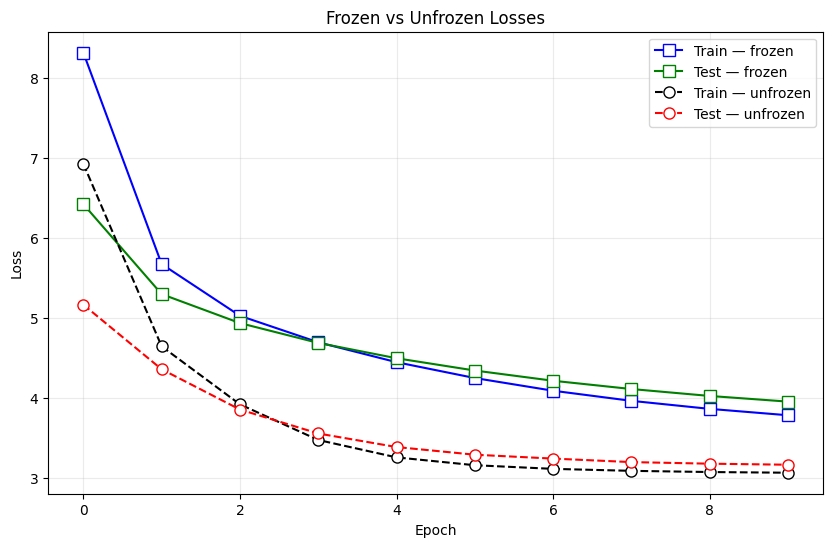

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(train_losses_freezed, 'bs-', markerfacecolor='w', markersize=8, label='Train — frozen')
plt.plot(test_losses_freezed, 'gs-', markerfacecolor='w', markersize=8, label='Test — frozen')

plt.plot(train_losses_unfreezed, 'ko--', markerfacecolor='w', markersize=8, label='Train — unfrozen')
plt.plot(test_losses_unfreezed, 'ro--', markerfacecolor='w', markersize=8, label='Test — unfrozen')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Frozen vs Unfrozen Losses')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# Generate

In [24]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('gpt2')
tok_x = tokenizer.encode("My name is", return_tensors='pt').to(device)

for name, model in [
    ('Frozen:\n', model_freezed),
    ('Unfrozen:\n', model_unfreezed)
]:
    generated = model.generate(tok_x.clone(), n_tok_predict=30)
    print(f'\n{name} {tokenizer.decode(generated[0])}')


Frozen:
 My name is of rust by hasty conclusions such adiscover hands when I was
their eyes, you must be moon of desert. And yet.... It

Unfrozen:
 My name is meant by rolling in
’sensitiveness of the green; and travel _how This chill air whips. After the skin. Then I


## Conclusions

* Freezing weights is a common technique in deep learning for transfer learning or when re-training on limited data
* Freezing weights is not necessarily advantageous, especially in simple models or if the new training data differ from the previously trained data.

#